In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4911,8565-WUXZU,Male,1,Yes,No,72,Yes,No,Fiber optic,Yes,...,No,Yes,No,No,Two year,Yes,Credit card (automatic),84.80,6141.65,No
2412,1623-NLDOT,Female,0,Yes,No,42,No,No phone service,DSL,No,...,No,Yes,No,No,One year,No,Mailed check,33.55,1445.3,Yes
85,4445-ZJNMU,Male,0,No,No,9,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.30,918.75,No
823,0295-QVKPB,Male,0,No,No,5,Yes,No,DSL,No,...,Yes,Yes,Yes,No,Month-to-month,Yes,Credit card (automatic),63.95,318.1,No
621,0516-UXRMT,Female,0,No,No,62,Yes,Yes,Fiber optic,Yes,...,Yes,No,No,No,One year,Yes,Electronic check,92.05,5755.8,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [9]:
df.drop(columns=['customerID'],inplace=True)

In [10]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [11]:
df['Partner'].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

In [12]:
for col in df.columns:
    print(f"--{col}--")
    print(df[col].value_counts())
    print()

--gender--
gender
Male      3555
Female    3488
Name: count, dtype: int64

--SeniorCitizen--
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--Partner--
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--Dependents--
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--tenure--
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64

--PhoneService--
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--MultipleLines--
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--InternetService--
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--OnlineSecurity--
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--OnlineBackup--
OnlineBackup
No                

In [13]:
#for no internert service:
#OnlineSecurity,#Onlinebackup#DeviceProtection#TechSupport#StreamingTV#StreamingMovies

In [14]:
cols=['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
for coln in cols:
    df[coln]=df[coln].replace('No internet service','No')
    

In [15]:
df['MultipleLines']=df['MultipleLines'].replace('No phone service','No')

In [16]:
df.sample(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6125,Male,0,Yes,No,13,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),102.25,1359.00,Yes
5397,Male,0,No,No,6,Yes,No,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,84.85,523.50,Yes
2863,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,44.60,44.60,No
2854,Male,0,Yes,Yes,17,Yes,Yes,DSL,Yes,No,Yes,No,Yes,No,One year,Yes,Bank transfer (automatic),70.35,1201.65,No
5416,Female,0,Yes,Yes,57,Yes,No,Fiber optic,No,Yes,No,No,Yes,Yes,One year,Yes,Electronic check,95.00,5535.80,No


In [17]:
df['Partner']=df['Partner'].map({'Yes':1,'No':0})
df['Dependents']=df['Dependents'].map({'Yes':1,'No':0})
df['PhoneService']=df['PhoneService'].map({'Yes':1,'No':0})
df['OnlineBackup']=df['OnlineBackup'].map({'Yes':1,'No':0})
df['StreamingMovies']=df['StreamingMovies'].map({'Yes':1,'No':0})
df['StreamingTV']=df['StreamingTV'].map({'Yes':1,'No':0})
df['PaperlessBilling']=df['PaperlessBilling'].map({'Yes':1,'No':0})
df['TechSupport']=df['TechSupport'].map({'Yes':1,'No':0})
df['DeviceProtection']=df['DeviceProtection'].map({'Yes':1,'No':0})
df['gender']=df['gender'].map({'Male':1,'Female':0})
df['OnlineSecurity']=df['OnlineSecurity'].map({'Yes':1,'No':0})
df['MultipleLines']=df['MultipleLines'].map({'Yes':1,'No':0})
df['Churn']=df['Churn'].map({'Yes':1,'No':0})
df.drop(columns=['MonthlyCharges'],inplace=True)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   int64  
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   int64  
 9   OnlineBackup      7043 non-null   int64  
 10  DeviceProtection  7043 non-null   int64  
 11  TechSupport       7043 non-null   int64  
 12  StreamingTV       7043 non-null   int64  
 13  StreamingMovies   7043 non-null   int64  
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   str    
 17  TotalC

In [19]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [20]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [21]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

DISTRIBUTION

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5]),
 [Text(0.5, 0, 'gender'),
  Text(1.5, 0, 'SeniorCitizen'),
  Text(2.5, 0, 'Partner'),
  Text(3.5, 0, 'Dependents'),
  Text(4.5, 0, 'tenure'),
  Text(5.5, 0, 'PhoneService'),
  Text(6.5, 0, 'MultipleLines'),
  Text(7.5, 0, 'OnlineSecurity'),
  Text(8.5, 0, 'OnlineBackup'),
  Text(9.5, 0, 'DeviceProtection'),
  Text(10.5, 0, 'TechSupport'),
  Text(11.5, 0, 'StreamingTV'),
  Text(12.5, 0, 'StreamingMovies'),
  Text(13.5, 0, 'PaperlessBilling'),
  Text(14.5, 0, 'TotalCharges'),
  Text(15.5, 0, 'Churn')])

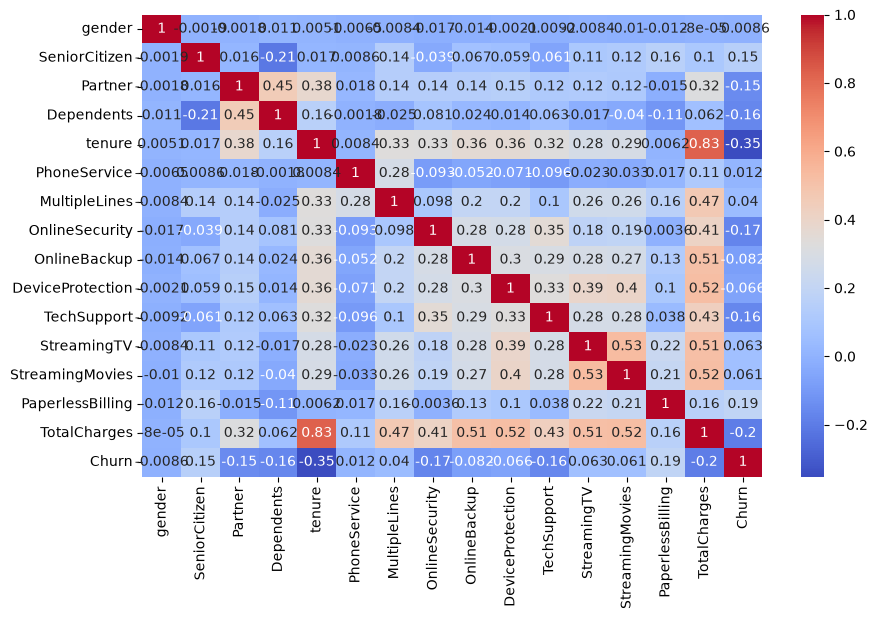

In [22]:
corr_matrix=df.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm')
plt.xticks(rotation=90)


I find gender is not responsible for churn or can say correlation betn them is very much low.tenure and totalCharges is seen to be correlated with Online Services columns


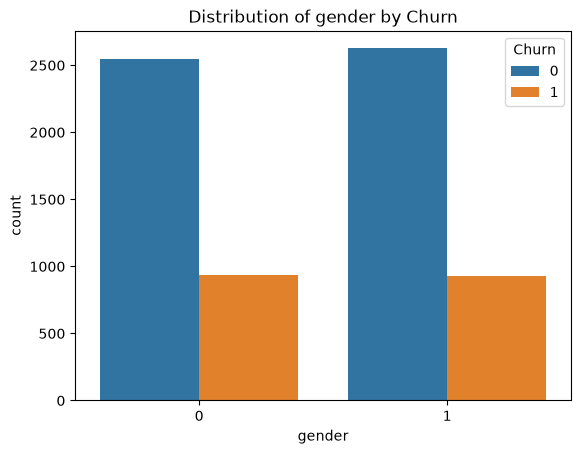

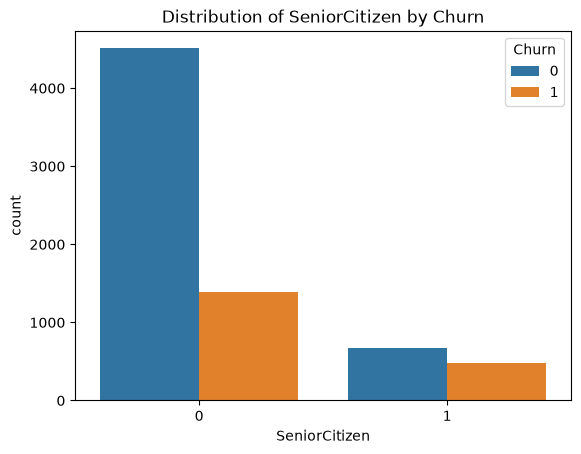

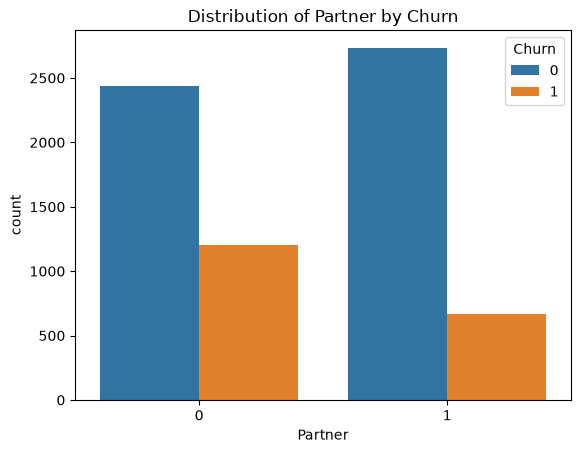

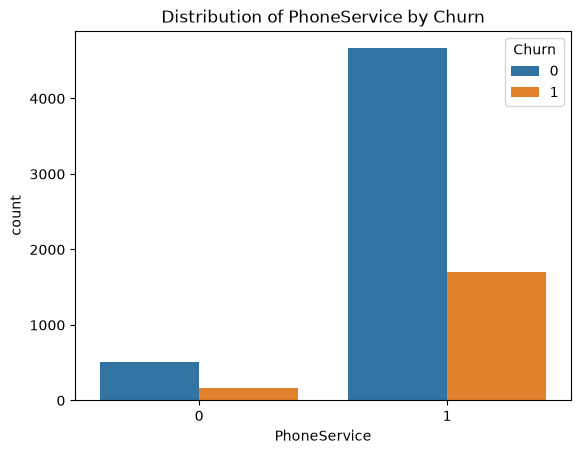

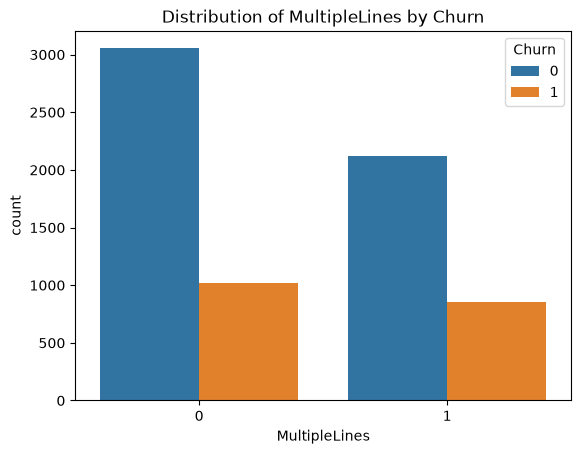

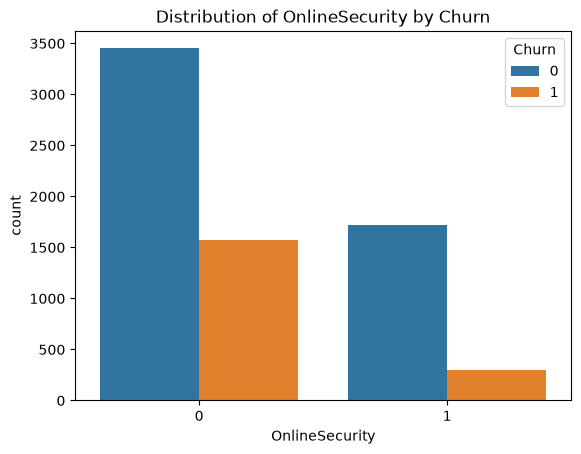

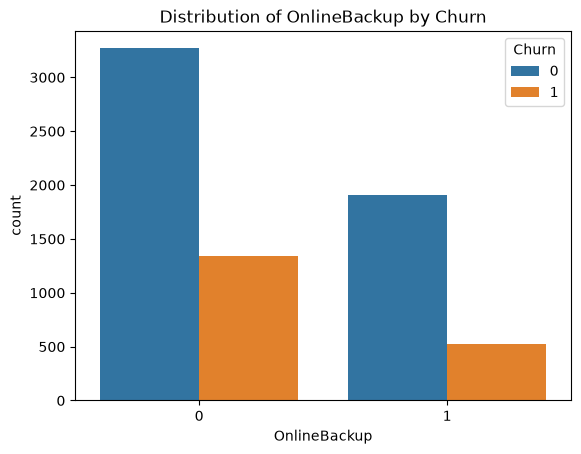

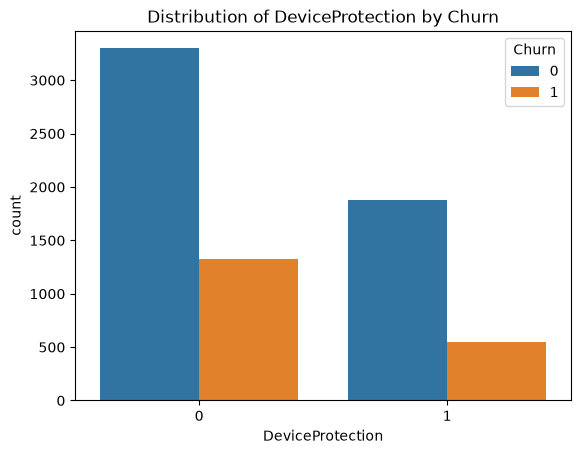

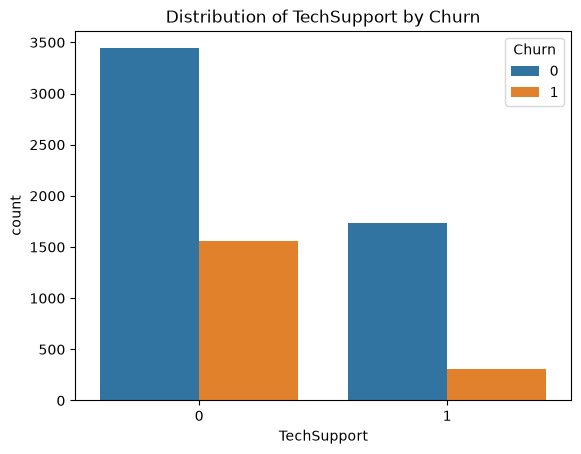

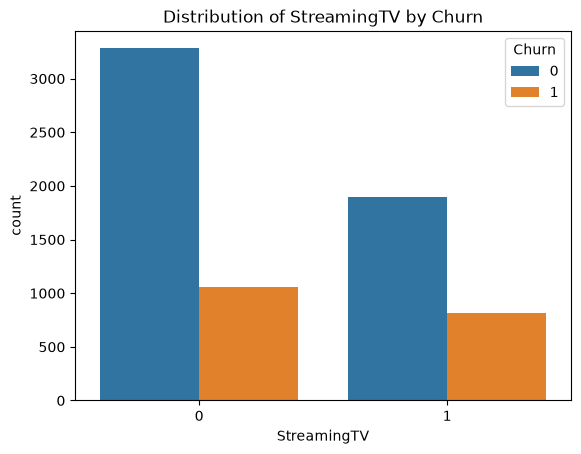

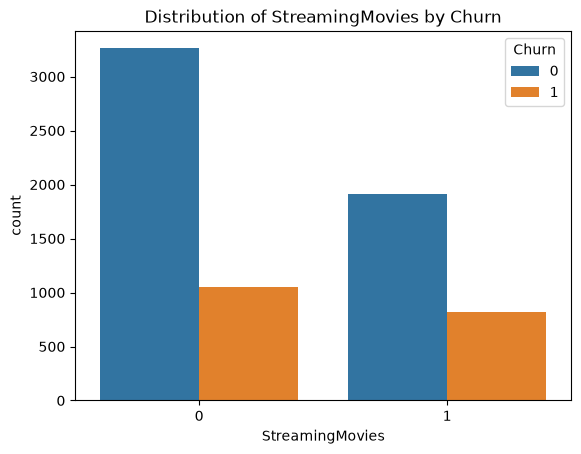

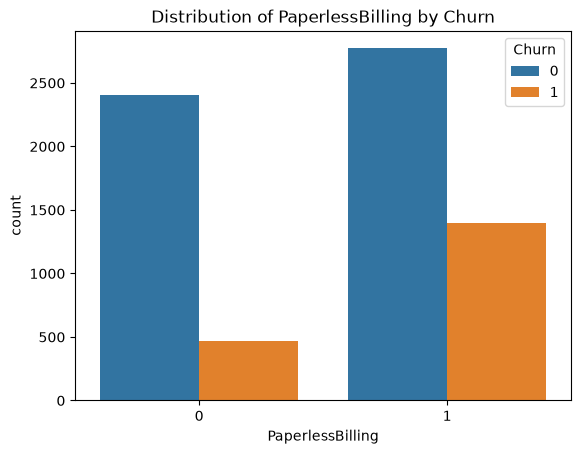

In [23]:
colm=['gender','SeniorCitizen','Partner','PhoneService','MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','PaperlessBilling']
for i,col in enumerate(colm):
    sns.countplot(data=df,x=col,hue='Churn')
    plt.title(f"Distribution of {col} by Churn")
    plt.show()

PREPROCESSING

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report,accuracy_score,r2_score,f1_score,mean_squared_error
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV
from xgboost import XGBClassifier


In [25]:
X=df.drop(columns=['Churn'])
y=df['Churn']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)


In [26]:
from sklearn.impute import SimpleImputer
cat_cols=['InternetService','PaymentMethod']
ord_cols=['Contract']
num_cols=X_train.select_dtypes(include='number').columns.tolist()

In [27]:
cat_cols
df['Contract'].value_counts()


Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [28]:
preprocessing=ColumnTransformer(
    transformers=[
        ('cat_cols',OneHotEncoder(handle_unknown='ignore'),cat_cols),
        ('ord_cols',OrdinalEncoder(categories=[['Month-to-month','One year','Two year']]),ord_cols),
        ('num_cols',StandardScaler(),num_cols)
    ],remainder='passthrough'
    
)

In [29]:
model=Pipeline(
    steps=[
        ('preprocessing',preprocessing),
        ('classifier',LogisticRegression(max_iter=2000))
    ]
)

LOGISTIC REGRESSION

In [30]:
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
acc=accuracy_score(y_test,y_pred)
print("Accuracy:",acc)
f1=f1_score(y_test,y_pred)
print("F1 Score:",f1)
print("")
class_report=classification_report(y_test,y_pred)
print("Classification Report:",class_report)
from sklearn.metrics import roc_auc_score

test_proba = model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, test_proba))

print()

Accuracy: 0.8204400283889283
F1 Score: 0.6390870185449358

Classification Report:               precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409

ROC-AUC: 0.8622291862908484



In [31]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['lbfgs', 'liblinear']
}
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best CV ROC-AUC:", grid.best_score_)

best_model = grid.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': 100, 'classifier__solver': 'lbfgs'}
Best CV ROC-AUC: 0.8410698823930858


In [32]:
test_proba=best_model.predict_proba(X_test)[:,1]

In [33]:
print("Tuned Test ROC-AUC:",
      roc_auc_score(y_test,test_proba))

Tuned Test ROC-AUC: 0.8623559886964712


RANDOM FOREST

In [34]:
rf_model = Pipeline([
    ('preprocessing', preprocessing),
    ('classifier', RandomForestClassifier(random_state=42))
])
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

In [35]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_proba))

Accuracy: 0.7877927608232789
              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1036
           1       0.64      0.45      0.53       373

    accuracy                           0.79      1409
   macro avg       0.73      0.68      0.70      1409
weighted avg       0.77      0.79      0.77      1409

ROC-AUC: 0.8356291469562247


In [36]:
param_dist = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [None, 5, 10, 15, 20],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4, 6],
    'classifier__max_features': ['sqrt', 'log2', 0.5]
}

In [37]:

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=25,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)
print(rf_search.best_params_)
print(rf_search.best_score_)

best_rf = rf_search.best_estimator_

Fitting 5 folds for each of 25 candidates, totalling 125 fits
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 10}
0.8420805887431699


In [38]:
rf_pred_tuned = best_rf.predict(X_test)
rf_proba_tuned = best_rf.predict_proba(X_test)[:, 1]
print("Accuracy:",
      accuracy_score(y_test, rf_pred_tuned))
print(classification_report(y_test, rf_pred_tuned))
print("ROC-AUC:",
      roc_auc_score(y_test, rf_proba_tuned))

Accuracy: 0.8126330731014905
              precision    recall  f1-score   support

           0       0.84      0.92      0.88      1036
           1       0.70      0.51      0.59       373

    accuracy                           0.81      1409
   macro avg       0.77      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.866068193816183


XGBOOST

In [39]:
xgb_model = Pipeline([
    ('preprocessing', preprocessing),
    ('classifier', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred))
print(" ")
print("ROC-AUC:", roc_auc_score(y_test, xgb_proba))

Accuracy: 0.7863733144073811
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1036
           1       0.61      0.52      0.56       373

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

 
ROC-AUC: 0.8389622387611663


In [40]:
param_dist_xgb = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [2, 3, 4, 5, 7],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'classifier__min_child_weight': [1, 3, 5, 7],
    'classifier__gamma': [0, 0.1, 0.3, 0.5]
}
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist_xgb,
    n_iter=30,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)
print(xgb_search.best_params_)
print(xgb_search.best_score_)

best_xgb = xgb_search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'classifier__subsample': 0.8, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 1, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0, 'classifier__colsample_bytree': 0.7}
0.8453979883682317


In [41]:
xgb_pred_tuned = best_xgb.predict(X_test)
xgb_proba_tuned = best_xgb.predict_proba(X_test)[:, 1]
print(classification_report(y_test, xgb_pred_tuned))

print("ROC-AUC:",
      roc_auc_score(y_test, xgb_proba_tuned))

              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1036
           1       0.69      0.54      0.61       373

    accuracy                           0.81      1409
   macro avg       0.77      0.73      0.74      1409
weighted avg       0.81      0.81      0.81      1409

ROC-AUC: 0.8636977651722961


In [64]:
from sklearn.metrics import classification_report, confusion_matrix
y_proba = best_xgb.predict_proba(X_test)[:, 1]
threshold = 0.35
y_pred = (y_proba >= threshold).astype(int)
print("Threshold:", threshold)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


Threshold: 0.35
              precision    recall  f1-score   support

           0       0.90      0.82      0.86      1036
           1       0.60      0.75      0.67       373

    accuracy                           0.80      1409
   macro avg       0.75      0.79      0.76      1409
weighted avg       0.82      0.80      0.81      1409

[[853 183]
 [ 94 279]]


In [65]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'Logistic Regression': best_model,
    'Random Forest': best_rf,
    'XGBoost': best_xgb
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba)
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0  Logistic Regression     0.820      0.682   0.603     0.640    0.862
1        Random Forest     0.813      0.700   0.512     0.591    0.866
2              XGBoost     0.815      0.690   0.544     0.609    0.864


In [66]:
balanced_lr = Pipeline([
    ('preprocessing', preprocessing),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs']
}

balanced_search = GridSearchCV(
    balanced_lr,
    param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

balanced_search.fit(X_train, y_train)

best_balanced_lr = balanced_search.best_estimator_
y_pred = best_balanced_lr.predict(X_test)
y_proba = best_balanced_lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
              precision    recall  f1-score   support

           0       0.92      0.72      0.81      1036
           1       0.52      0.83      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.78      0.72      1409
weighted avg       0.81      0.75      0.77      1409

[[750 286]
 [ 64 309]]
ROC-AUC: 0.8622162472698667


In [68]:
final_model=best_balanced_lr

In [69]:
import joblib
joblib.dump(final_model,'cusomer_churn_model.joblib')

['cusomer_churn_model.joblib']